# Speed comparison: `DurableModel` vs `DurableModel_Fast`

Finite-horizon lifecycle, $T=10$ periods (`cycles=1`, `T_cycle=10`).
Parameters follow `DurableModel_Combined_Inf_Test.ipynb` with search $S=0.2$ and price $\sigma_p=0.1$.

In [1]:
import copy
import os
import time

import numpy as np
import matplotlib.pyplot as plt
from joblib import cpu_count
from numba import config as numba_config

from DurableModel import DurableConsumer as DurableSlow
from DurableModel_Fast import (
    DurableConsumer as DurableFast,
    _GPU_AVAILABLE,
    _USE_GPU_FOC,
)

print("CUDA_PATH:", os.environ.get("CUDA_PATH"))
print("GPU available:", _GPU_AVAILABLE)
print("GPU FOC path (DCEGM_GPU_FOC):", _USE_GPU_FOC)
print("joblib cpu_count:", cpu_count())
print("NUMBA_NUM_THREADS:", numba_config.NUMBA_NUM_THREADS)
if _GPU_AVAILABLE:
    import DurableModel_Fast as _F
    props = _F._cp.cuda.runtime.getDeviceProperties(0)
    name = props["name"]
    print("GPU:", name.decode() if isinstance(name, bytes) else name)

CUDA_PATH: C:\Users\amonninger\AppData\Local\miniconda3\envs\DCEGM_Search_env
GPU available: True
GPU FOC path (DCEGM_GPU_FOC): False
joblib cpu_count: 24
NUMBA_NUM_THREADS: 24
GPU: NVIDIA RTX PRO 3000 Blackwell Generation Laptop GPU


In [2]:
durable_defaults = dict(
    CRRA=2.0,
    DiscFac=0.975,
    LivPrb=1.0,
    alpha=0.75,
    d_ubar=1e-4,
    dDepr=0.05,
    adjC=0.10,
    MaintCost=0.0,
    OpCost=0.0,
    Rfree=1.04**(0.25),
    RSpread=0.0,
    PermGroFac=1.0,
    LTV=0.0,
    BoroCnstArt=0.0,
    PermShkStd=0.0,
    PermShkCount=1,
    TranShkStd=0.2,
    TranShkCount=7,
    UnempPrb=0.0,
    IncUnemp=0.0,
    IncUnemp_Std=0.1,
    truncation=2,
    taxrate=0.0,
    labor=1.0,
    wage=1.0,
    sigma_eps=0.0,
    SearchCost=0.1,
    ScaleBool=False,
    e_grid_count=101,
    PriceShkCount=5,
    PriceShkStd=0.1,
    use_expected=False,
    use_TransitionMatrix=True,
    nNrmMax=10,
    nNrmCount=200,
    mNrmMax=16.0,
    mNrmCount=200,
    xNrmMax=26,
    xNrmCount=400,
    aNrmMax=16.0,
    aNrmCount=200,
    NestFac=1,
    grid_type="exp_mult",
    TranMatrix_mCount=1010,
    TranMatrix_bCount=1000,
    N_scan=800,
    cycles=1,
    T_cycle=10,
    tol=1e-8,
    max_cycles=500,
    distance_metric="mse",
    verbose=False,
)

params = copy.deepcopy(durable_defaults)
params["sigma_eps"] = 0.0
params["SearchCost"] = 0.2
params["PriceShkStd"] = 0.1
params["PriceShkCount"] = 5
params["TranMatrixmCount"] = 250
params["TranMatrixmMax"] = durable_defaults["mNrmMax"]
params["TranMatrixnMax"] = durable_defaults["nNrmMax"]
params["diagnostics"] = False
params["cycles"] = 1
params["T_cycle"] = 10

In [3]:
# Probe: Numba-parallel FOC vs GPU FOC vs GPU interpolant (warmup already done at import).
from DurableModel_Fast import _cpu_foc_roots, _gpu_foc_ctx, _gpu_foc_from_ctx, _eval_lf
from utility import construct_grid
from HARK.econforgeinterp import LinearFast
import DurableModel_Fast as _F

dGrid = np.linspace(0, 10, 200)
aGrid = np.linspace(0, 16, 200)
rng = np.random.default_rng(0)
eop1 = rng.random((200, 200)) + 0.1
eopd = rng.random((200, 200)) + 0.1
d_adj = np.asarray(construct_grid(0, 10, 400, "exp_mult", 1), dtype=float)
a_scan = np.asarray(construct_grid(0, 16, 800, "exp_mult", 1), dtype=float)
alpha, d_ubar, CRRA, price = 0.75, 1e-4, 2.0, 1.0

t0 = time.perf_counter()
ar, _ = _cpu_foc_roots(d_adj, a_scan, dGrid, aGrid, eop1, eopd, price, alpha, d_ubar, CRRA)
t_cpu = time.perf_counter() - t0
t0 = time.perf_counter()
_cpu_foc_roots(d_adj, a_scan, dGrid, aGrid, eop1, eopd, price, alpha, d_ubar, CRRA)
t_cpu2 = time.perf_counter() - t0
print(f"CPU Numba FOC (prange): {t_cpu:.3f}s  then {t_cpu2:.3f}s  nroots={len(ar)}")

if _GPU_AVAILABLE:
    ctx = _gpu_foc_ctx(d_adj, a_scan, dGrid, aGrid, eop1, eopd)
    t0 = time.perf_counter()
    ag, _ = _gpu_foc_from_ctx(ctx, price, alpha, d_ubar, CRRA)
    _F._cp.cuda.runtime.deviceSynchronize()
    t_gpu = time.perf_counter() - t0
    print(f"GPU FOC:                {t_gpu:.3f}s  nroots={len(ag)}")

    xq = np.repeat(dGrid[:, None], len(aGrid), axis=1).ravel()
    yq = np.tile(aGrid, len(dGrid))
    lf = LinearFast(eop1, [dGrid, aGrid])
    t0 = time.perf_counter()
    _ = lf(xq, yq)
    t_lf = time.perf_counter() - t0
    t0 = time.perf_counter()
    _ = _eval_lf(lf, xq, yq)
    _F._cp.cuda.runtime.deviceSynchronize()
    t_gi = time.perf_counter() - t0
    print(f"LinearFast {len(xq):,} pts: {t_lf:.4f}s")
    print(f"GPU interp {len(xq):,} pts: {t_gi:.4f}s")

CPU Numba FOC (prange): 0.396s  then 0.021s  nroots=27449
GPU FOC:                0.206s  nroots=27449
LinearFast 40,000 pts: 0.4949s
GPU interp 40,000 pts: 0.0020s


In [4]:
t0 = time.perf_counter()
model_slow = DurableSlow(**params)
model_slow.solve()
t_slow = time.perf_counter() - t0

t0 = time.perf_counter()
model_fast = DurableFast(**params)
model_fast.solve()
t_fast = time.perf_counter() - t0

print(f"old  DurableModel:      {t_slow:8.2f} s")
print(f"fast DurableModel_Fast: {t_fast:8.2f} s")
print(f"speedup:                {t_slow / t_fast:8.2f} x")

c:\Users\amonninger\AppData\Local\miniconda3\envs\DCEGM_Search_env\lib\site-packages\HARK\rewards.py:40: RuntimeWarning: divide by zero encountered in reciprocal
  return c ** (1.0 - rho) / (1.0 - rho)
c:\Users\amonninger\OneDrive - Texas A&M University\GitHub\AMonninger\DCEGM_Search\Code\DurableModel.py:582: RuntimeWarning: divide by zero encountered in power
  * C ** (self.alpha * (1.0 - self.CRRA) - 1.0)
c:\Users\amonninger\OneDrive - Texas A&M University\GitHub\AMonninger\DCEGM_Search\Code\DurableModel.py:589: RuntimeWarning: divide by zero encountered in power
  * (C ** (self.alpha * (1.0 - self.CRRA)))
c:\Users\amonninger\AppData\Local\miniconda3\envs\DCEGM_Search_env\lib\site-packages\HARK\rewards.py:40: RuntimeWarning: divide by zero encountered in reciprocal
  return c ** (1.0 - rho) / (1.0 - rho)
c:\Users\amonninger\OneDrive - Texas A&M University\GitHub\AMonninger\DCEGM_Search\Code\DurableModel.py:589: RuntimeWarning: divide by zero encountered in power
  * (C ** (self.alpha

old  DurableModel:          8.75 s
fast DurableModel_Fast:     1.56 s
speedup:                    5.60 x


max |Δ cAdj| = 5.929e-14
max |Δ dAdj| = 2.252e-13


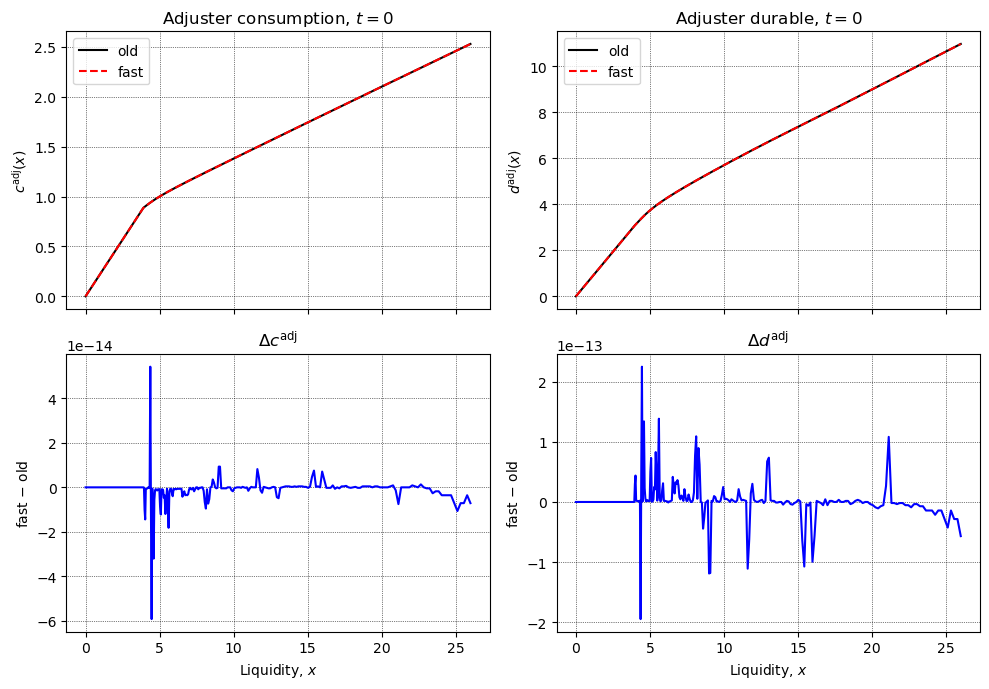

In [5]:
sol_s = model_slow.solution[0]
sol_f = model_fast.solution[0]
x = model_slow.xNrmGrid

c_s = np.maximum(sol_s.cFuncAdj_1d(x), 0.0)
c_f = np.maximum(sol_f.cFuncAdj_1d(x), 0.0)
d_s = np.maximum(sol_s.dFuncAdj_1d(x), 0.0)
d_f = np.maximum(sol_f.dFuncAdj_1d(x), 0.0)

print(f"max |Δ cAdj| = {np.nanmax(np.abs(c_f - c_s)):.3e}")
print(f"max |Δ dAdj| = {np.nanmax(np.abs(d_f - d_s)):.3e}")

fig, axes = plt.subplots(2, 2, figsize=(10, 7), sharex=True)
axes[0, 0].plot(x, c_s, "k-", label="old")
axes[0, 0].plot(x, c_f, "r--", label="fast")
axes[0, 0].set_ylabel(r"$c^{\mathrm{adj}}(x)$")
axes[0, 0].set_title("Adjuster consumption, $t=0$")
axes[0, 0].legend()
axes[0, 0].grid(color="k", linestyle=":", linewidth=0.5)

axes[0, 1].plot(x, d_s, "k-", label="old")
axes[0, 1].plot(x, d_f, "r--", label="fast")
axes[0, 1].set_ylabel(r"$d^{\mathrm{adj}}(x)$")
axes[0, 1].set_title("Adjuster durable, $t=0$")
axes[0, 1].legend()
axes[0, 1].grid(color="k", linestyle=":", linewidth=0.5)

axes[1, 0].plot(x, c_f - c_s, "b-")
axes[1, 0].set_xlabel(r"Liquidity, $x$")
axes[1, 0].set_ylabel(r"fast $-$ old")
axes[1, 0].set_title(r"$\Delta c^{\mathrm{adj}}$")
axes[1, 0].grid(color="k", linestyle=":", linewidth=0.5)

axes[1, 1].plot(x, d_f - d_s, "b-")
axes[1, 1].set_xlabel(r"Liquidity, $x$")
axes[1, 1].set_ylabel(r"fast $-$ old")
axes[1, 1].set_title(r"$\Delta d^{\mathrm{adj}}$")
axes[1, 1].grid(color="k", linestyle=":", linewidth=0.5)

fig.tight_layout()
plt.show()